# 01 — Visualisation & Formatage des données eCO2mix (RTE)

**Objectifs (Étape 1 du cours) :**
1. Importation, formatage de l'index temporel (`DatetimeIndex`) et contrôle des valeurs manquantes.
2. Justification du choix de fréquence : comparaison **Journalier / Hebdomadaire ($s=52$) / Mensuel** (pourquoi le mensuel lisse excessivement les pics thermiques hivernaux).
3. Visualisation exploratoire : série brute, tendance long terme, profil saisonnier annuel (boxplots mensuels et superposition des années).

In [1]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import PROCESSED_DATA_DIR, FIGURES_DIR
from src.preprocessing import run_pipeline

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

run_pipeline()

df_jour = pd.read_parquet(PROCESSED_DATA_DIR / "eco2_france_jour.parquet")
df_jour["date"] = pd.to_datetime(df_jour["date"])
df_jour = df_jour.set_index("date").asfreq("D")

df_hebdo = pd.read_parquet(PROCESSED_DATA_DIR / "eco2_france_hebdo.parquet")
df_hebdo["semaine"] = pd.to_datetime(df_hebdo["semaine"])
df_hebdo = df_hebdo.set_index("semaine")

print("Valeurs manquantes (série journalière réindexée) :", df_jour["conso_gwh"].isna().sum())
display(df_hebdo.head())

[OK] eco2_france_jour.parquet : 5357 jours (2012-01-01 -> 2026-08-31)
[OK] eco2_france_hebdo.parquet : 765 semaines complètes
Valeurs manquantes (série journalière réindexée) : 0


,conso_gwh,puissance_moy_mw,nb_jours
semaine,,,
2012-01-02,10965.2445,65269.312500,7
2012-01-09,11598.6945,69039.848214,7
2012-01-16,11895.7040,70807.761905,7
2012-01-23,11326.9735,67422.461310,7
2012-01-30,14048.2715,83620.663690,7


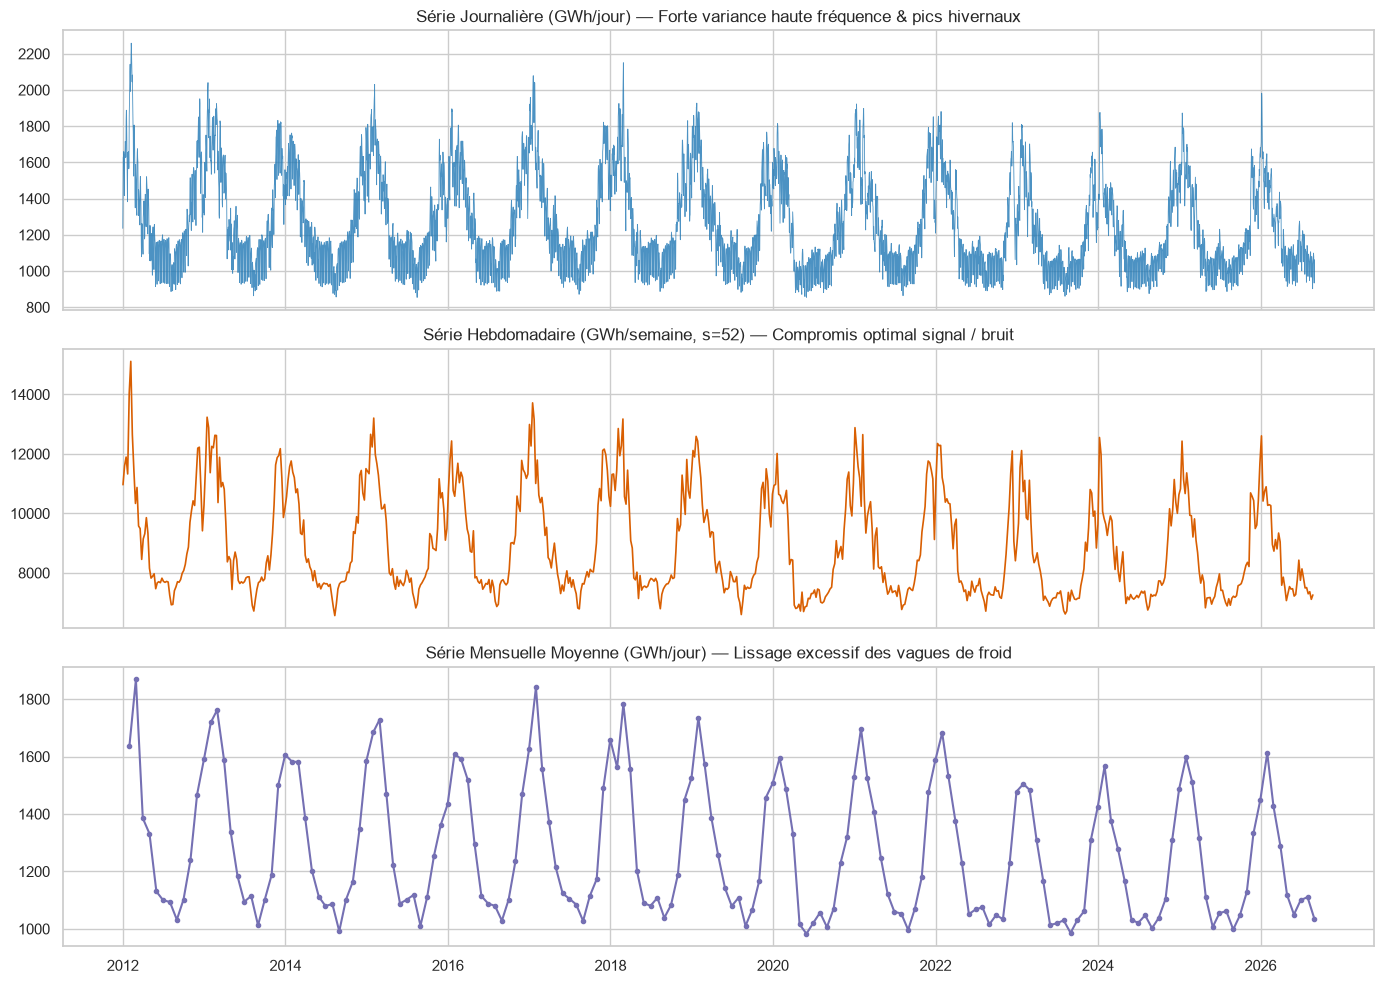

In [2]:
# 1. Visualisation de la série brute : Journalier vs Hebdomadaire vs Mensuel
df_mensuel = df_jour["conso_gwh"].resample("ME").mean()

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)

axes[0].plot(df_jour.index, df_jour["conso_gwh"], linewidth=0.6, alpha=0.8, color="#1f77b4")
axes[0].set_title("Série Journalière (GWh/jour) — Forte variance haute fréquence & pics hivernaux")

axes[1].plot(df_hebdo.index, df_hebdo["conso_gwh"], linewidth=1.2, color="#d95f02")
axes[1].set_title("Série Hebdomadaire (GWh/semaine, s=52) — Compromis optimal signal / bruit")

axes[2].plot(df_mensuel.index, df_mensuel, marker="o", markersize=3, linewidth=1.5, color="#7570b3")
axes[2].set_title("Série Mensuelle Moyenne (GWh/jour) — Lissage excessif des vagues de froid")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_visualisation_frequences.png", dpi=200)
plt.show()

/var/folders/pp/z7vtd9gd45b7rvt7lk7hjq0h0000gn/T/ipykernel_12005/1076089005.py:4: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  df_jour["jour_annee"] = df_jour.index.dayofyear
/var/folders/pp/z7vtd9gd45b7rvt7lk7hjq0h0000gn/T/ipykernel_12005/1076089005.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_jour, x="mois", y="conso_gwh", ax=axes[0], palette="coolwarm_r")


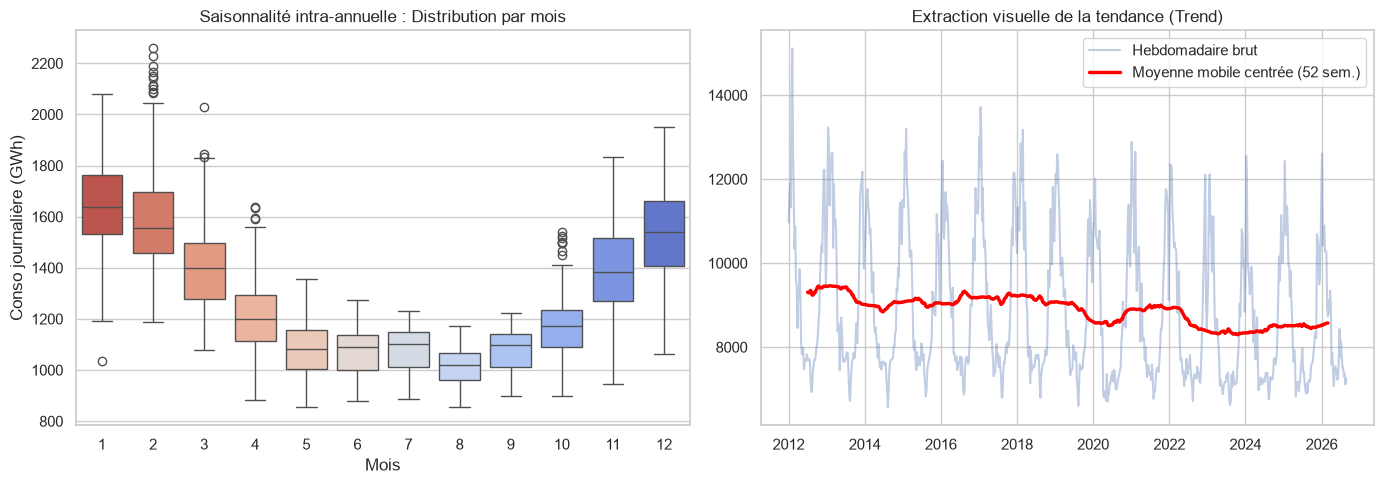

In [3]:
# 2. Mise en évidence de la saisonnalité et des ruptures annuelles
df_jour["annee"] = df_jour.index.year
df_jour["mois"] = df_jour.index.month
df_jour["jour_annee"] = df_jour.index.dayofyear

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df_jour, x="mois", y="conso_gwh", ax=axes[0], palette="coolwarm_r")
axes[0].set_title("Saisonnalité intra-annuelle : Distribution par mois")
axes[0].set_xlabel("Mois")
axes[0].set_ylabel("Conso journalière (GWh)")

# Moyenne glissante 52 semaines pour isoler visuellement le Trend
trend_52w = df_hebdo["conso_gwh"].rolling(window=52, center=True).mean()
axes[1].plot(df_hebdo.index, df_hebdo["conso_gwh"], alpha=0.35, label="Hebdomadaire brut")
axes[1].plot(trend_52w.index, trend_52w, color="red", linewidth=2.5, label="Moyenne mobile centrée (52 sem.)")
axes[1].set_title("Extraction visuelle de la tendance (Trend)")
axes[1].legend()

plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_saisonnalite_trend_visuel.png", dpi=200)
plt.show()